# EDA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv('modified_data\\wdi.csv')

In [3]:
df.columns

Index(['Unnamed: 0', 'economy', 'Series', 'Country', 'year', 'value',
       'value_scaled'],
      dtype='str')

In [4]:
df = df[['Country', 'economy', 'Series', 'year', 'value_scaled']]

In [5]:
df.Series.unique()

<ArrowStringArray>
['Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)',
             'Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)',
         'Renewable energy consumption (% of total final energy consumption)',
                               'Energy use (kg of oil equivalent per capita)',
                                         'GDP per capita (constant 2015 US$)',
               'Energy intensity (kg oe per constant 2015 US$ GDP) [derived]']
Length: 6, dtype: str

In [11]:
df_wide = (df.pivot_table(index=["Country", "year"],
                          columns="Series",
                          values="value_scaled")
             .reset_index())

df_wide = df_wide.rename(columns={
    "Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)": "ghg_pc",
    "Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)": "carbon_int_gdp",
    'Energy intensity (kg oe per constant 2015 US$ GDP) [derived]': "energy_int_gdp",
    "Renewable energy consumption (% of total final energy consumption)": "res_share",
    "Energy use (kg of oil equivalent per capita)": "energy_pc",
    "GDP per capita (constant 2015 US$)": "gdp_pc",

})

df_wide.columns.name = None
print(df_wide.shape)
df_wide.head()

(4416, 8)


,Country,year,carbon_int_gdp,energy_int_gdp,energy_pc,gdp_pc,res_share,ghg_pc
0,Albania,1990,3.765618,2.948070,0.813445,-0.963894,-2.138792,1.530003
1,Albania,1991,3.217255,2.773759,-0.621923,-1.315289,-1.053111,0.139315
2,Albania,1992,0.733200,1.446898,-1.543458,-1.376436,0.944542,-1.524612
3,Albania,1993,0.245119,0.943823,-1.578781,-1.288237,1.567000,-1.479929
4,Albania,1994,0.167542,0.868089,-1.405809,-1.202992,1.610427,-1.041313


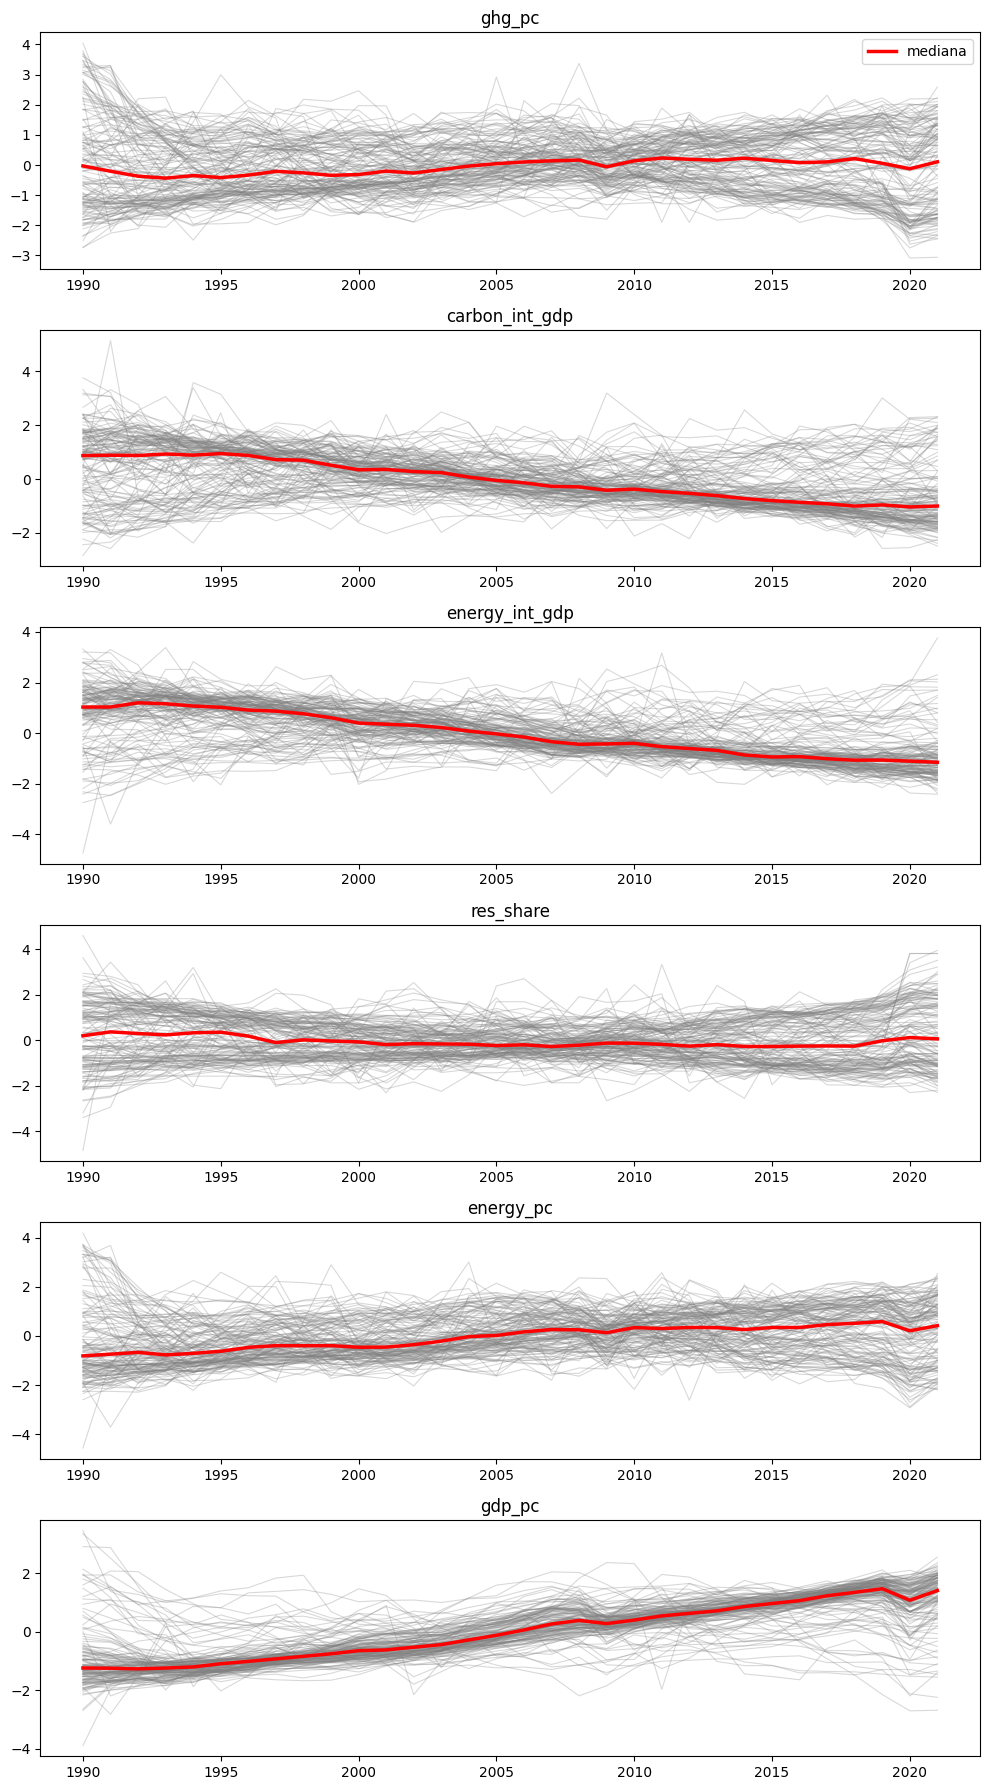

In [13]:

wskazniki = [ "ghg_pc", "carbon_int_gdp", "energy_int_gdp", "res_share", "energy_pc", "gdp_pc"]
fig, axes = plt.subplots(len(wskazniki), 1, figsize=(10, 3*len(wskazniki)))

for ax, w in zip(axes, wskazniki):
    for kraj, g in df_wide.groupby("Country"):
        ax.plot(g["year"], g[w], alpha=0.3, color="gray", linewidth=0.8)
    mediana = df_wide.groupby("year")[w].median()
    ax.plot(mediana.index, mediana.values, color="red", linewidth=2.5, label="mediana")
    ax.set_title(w)
axes[0].legend()
plt.tight_layout()
plt.savefig('attachments/overallSeries.jpg')
plt.show()



c:\Users\kjajk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\kjajk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\kjajk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\kjajk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\kjajk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, me

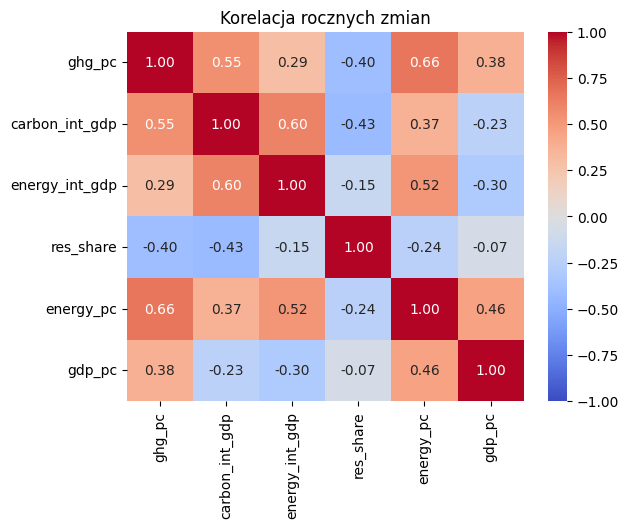

In [15]:

df_wide = df_wide.sort_values(["Country", "year"])
zmiany = df_wide[["Country", "year"]].copy()

for w in [ "ghg_pc", "carbon_int_gdp","energy_int_gdp", "energy_pc", "gdp_pc"]:
    zmiany[w] = df_wide.groupby("Country")[w].transform(lambda s: np.log(s).diff())

zmiany["res_share"] = df_wide.groupby("Country")["res_share"].diff()
zmiany = zmiany.dropna()

corr = zmiany[wskazniki].corr(method="spearman")
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Korelacja rocznych zmian")
plt.savefig('attachments/correlation.jpg',bbox_inches='tight')
plt.show()

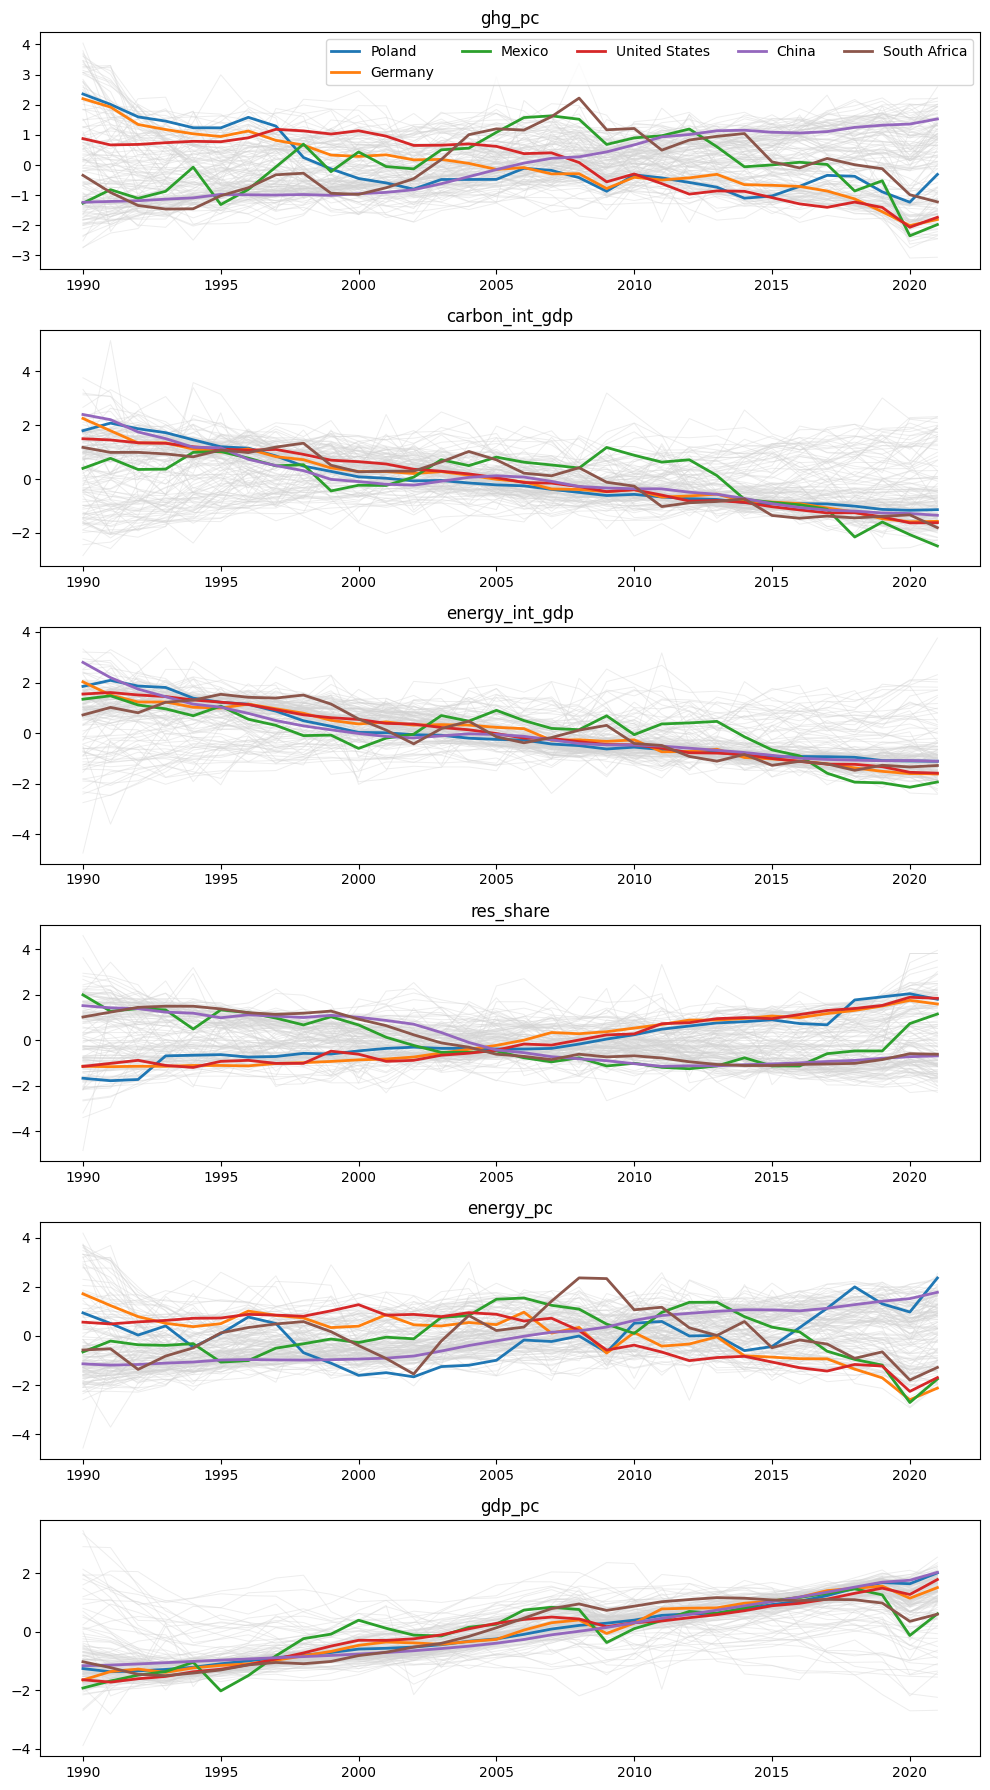

In [16]:
wybrane = ["Poland", "Germany", "Mexico", "United States", "China", "South Africa" ]

fig, axes = plt.subplots(len(wskazniki), 1, figsize=(10, 3*len(wskazniki)))
for ax, w in zip(axes, wskazniki):
    for kraj, g in df_wide.groupby("Country"):
        ax.plot(g["year"], g[w], color="lightgray", alpha=0.4, linewidth=0.7)
    for kraj in wybrane:
        g = df_wide[df_wide["Country"] == kraj]
        ax.plot(g["year"], g[w], linewidth=2, label=kraj)
    ax.set_title(w)
axes[0].legend(ncol=5)
plt.tight_layout()
fig.savefig('attachments/selectedCountries.jpg',bbox_inches='tight')
plt.show()

In [20]:
df_wide.to_csv('modified_data/wdiEDA.csv')